# 01 - Data acquisition & EDA
UCI Heart Disease (Cleveland, 303 patients, 13 features + diagnosis). The raw file has no header and marks missing values with `?`.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Image, display
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid")

In [2]:
from heart import config
from heart.data import build_clean_dataset, load_raw
raw = load_raw() if config.RAW_FILE.exists() else None
df = build_clean_dataset()
raw = load_raw()
print(raw.shape, df.shape)
df.head()

(303, 14) (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145.0,233.0,1,2,150.0,0,2.3,3,0.0,6.0,0
1,67,1,4,160.0,286.0,0,2,108.0,1,1.5,2,3.0,3.0,1
2,67,1,4,120.0,229.0,0,2,129.0,1,2.6,2,2.0,7.0,1
3,37,1,3,130.0,250.0,0,0,187.0,0,3.5,3,0.0,3.0,0
4,41,0,2,130.0,204.0,0,2,172.0,0,1.4,1,0.0,3.0,0


## Data quality
* `ca` has 4 and `thal` has 2 missing values. They are **kept as NaN** and imputed inside the model pipeline (median / mode), so the same rule is applied during training and in the API.
* The 0-4 `num` diagnosis is binarised: `target = num > 0`.

In [3]:
print(raw.isna().sum()[raw.isna().sum()>0])
df.describe().T.round(2)

ca      4
thal    2
dtype: int64


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


In [4]:
print(df.dtypes.value_counts()); print('duplicates:', df.duplicated().sum())

Int64      7
float64    6
int64      1
Name: count, dtype: int64
duplicates: 0


## Class balance
54 % no-disease / 46 % disease - mildly imbalanced, so stratified splits are used and `class_weight` is tuned.

INFO: saved /Users/jayaprakash/mlops_assignment/reports/figures/eda_class_balance.png


INFO: saved /Users/jayaprakash/mlops_assignment/reports/figures/eda_histograms.png


INFO: saved /Users/jayaprakash/mlops_assignment/reports/figures/eda_correlation_heatmap.png


INFO: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


...

INFO: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO: saved /Users/jayaprakash/mlops_assignment/reports/figures/eda_boxplots.png


INFO: saved /Users/jayaprakash/mlops_assignment/reports/figures/eda_missing_values.png


{
  "rows_raw": 303,
  "rows_clean": 303,
  "n_features": 13,
  "positive_rate": 0.4587,
  "missing_raw": {
    "ca": 4,
    "thal": 2
  },
  "top_target_correlations": {
    "thal": 0.526,
    "ca": 0.46,
    "exang": 0.432,
    "oldpeak": 0.425,
    "thalach": 0.417,
    "cp": 0.414
  }
}


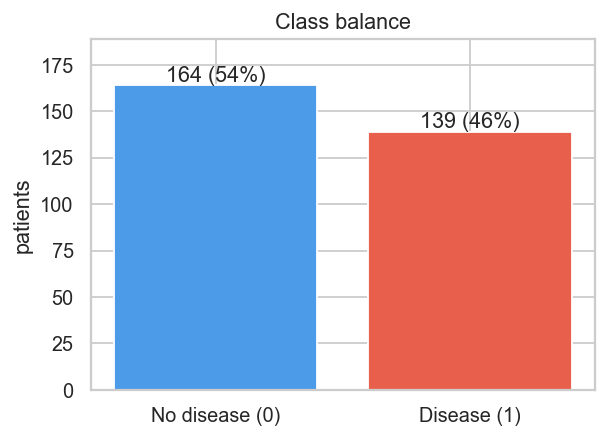

In [5]:
from heart import eda
stats = eda.main()
display(Image(config.FIGURES_DIR/'eda_class_balance.png'))

## Distributions of numeric features

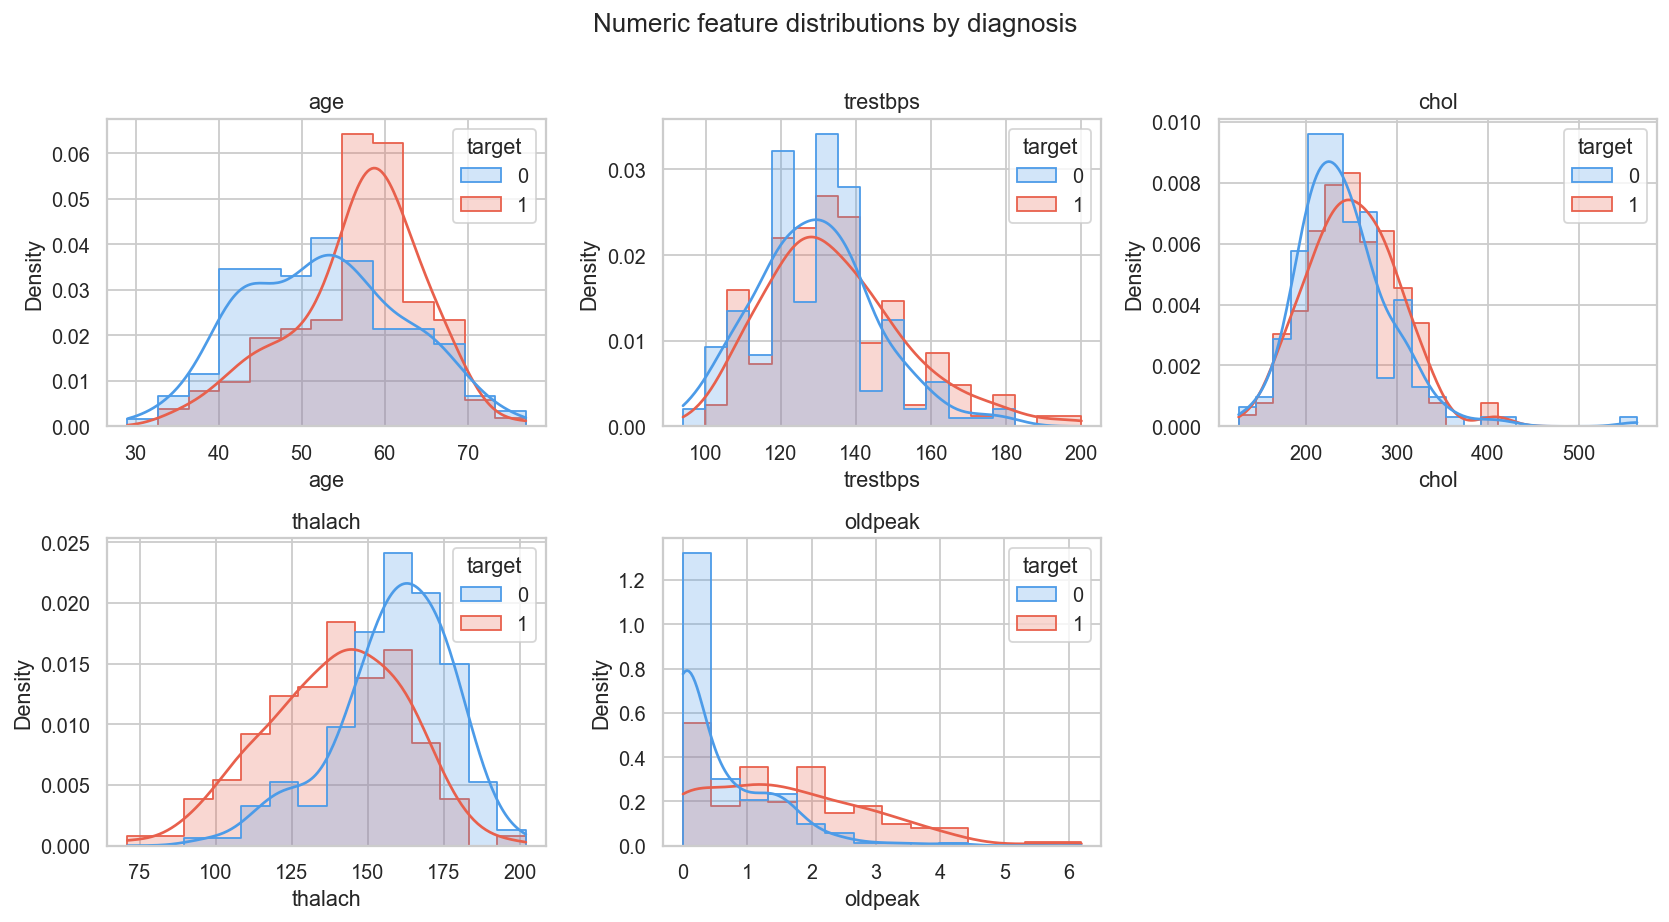

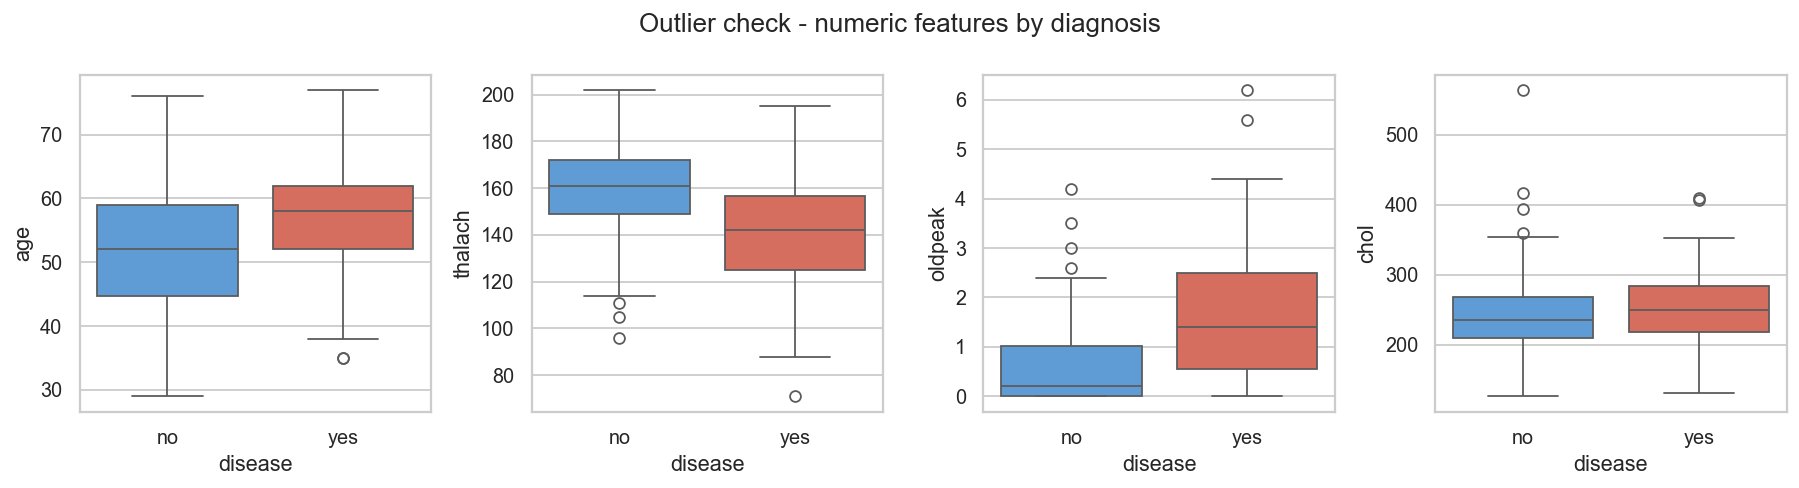

In [6]:
display(Image(config.FIGURES_DIR/'eda_histograms.png'))
display(Image(config.FIGURES_DIR/'eda_boxplots.png'))

Patients with disease reach a **lower peak heart rate** (`thalach`) and show **more ST depression** (`oldpeak`). Cholesterol separates the classes poorly. `chol` has a few high outliers (>400 mg/dl). They are plausible clinically, so they are kept, and they are handled by standard scaling.

## Correlation heatmap

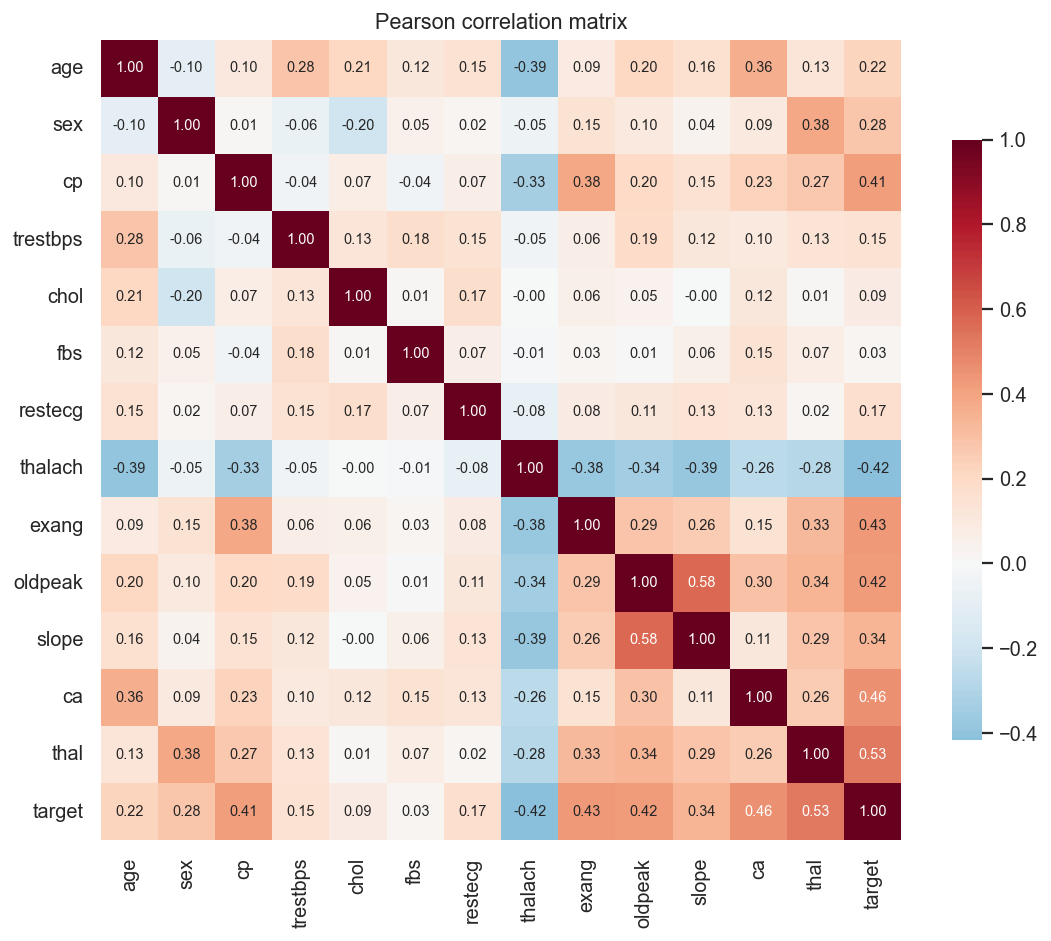

thal       0.526
ca         0.460
exang      0.432
oldpeak    0.425
thalach    0.417
cp         0.414
dtype: float64

In [7]:
display(Image(config.FIGURES_DIR/'eda_correlation_heatmap.png'))
pd.Series(stats['top_target_correlations'])

## Disease rate per categorical level

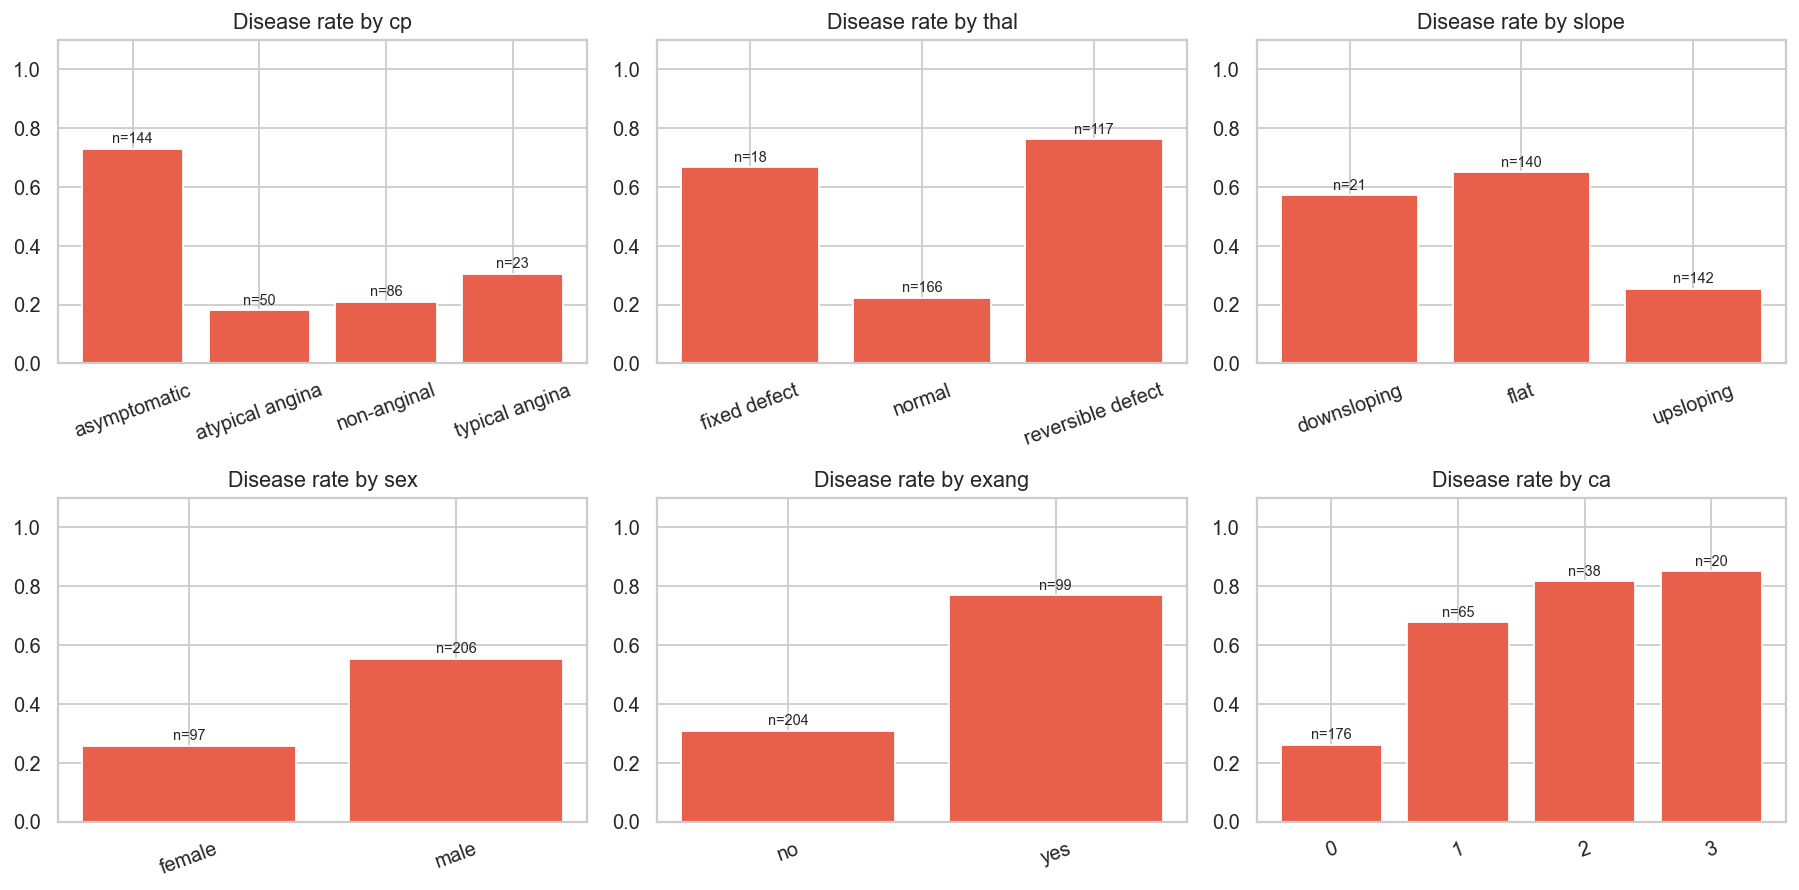

In [8]:
display(Image(config.FIGURES_DIR/'eda_categorical_disease_rate.png'))

**Takeaways for modelling**
* `cp`, `thal`, `slope` and `restecg` are nominal codes, so they are one-hot encoded. Treating them as ordinal numbers would be wrong.
* Asymptomatic chest pain (`cp=4`) and reversible thal defect (`thal=7`) have disease rates above 70 %.
* Engineered features: `hr_reserve_pct = thalach / (220 - age)` captures chronotropic incompetence. `chol_age_ratio` gives cholesterol relative to age.